# 3.Testing and Evaluation

This section reports the frozen test-set results, the baselines, the validation ablations, and the attention analysis. The test set has 1,838 questions. The validation set has 1,606 questions. Seeds are 4012, 4013, and 4014. A mean over seeds is accompanied by the sample standard deviation.

The main model, the B1 LSTM, and the B0 rules are scored again in this notebook on CPU and checked against the saved files. B2, B3, and the E4 training runs are read from the result files already in the repository. Each subsection names the script and the log that produced those files.

The next cell runs this file on its own. Delete it when the section is copied into the group notebook, which already defines `DEVICE`, `BASE_PATH`, and `tokenizer` in sections 0 and 1.


In [ ]:

# Standalone setup. Sections 0 and 1 of the group notebook already define
# DEVICE, BASE_PATH, and tokenizer. Section 1 loads ./tokenizer/piqa_bpe_v3.model
# after training it. This cell loads the committed model so the file can run alone.
import os
import sys
import time
import warnings
from pathlib import Path

import sentencepiece as spm
import torch

_root = Path.cwd().resolve()
for _candidate in [_root, *_root.parents]:
    if (_candidate / "scripts").is_dir() and (_candidate / "datasets" / "PIQA").is_dir():
        os.chdir(_candidate)
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break
else:
    raise FileNotFoundError("repository root (scripts/ and datasets/PIQA/) not found")

warnings.filterwarnings(
    "ignore",
    message="you are shuffling a 'StringArray' object",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="enable_nested_tensor is True",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="The PyTorch API of nested tensors is in prototype stage",
    category=UserWarning,
)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

BASE_PATH = Path("./datasets/PIQA")
tokenizer = spm.SentencePieceProcessor(model_file="scripts/tokenizer/piqa_bpe_v3.model")
_SECTION_STARTED = time.perf_counter()

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("vocab size:", tokenizer.get_piece_size())


Device: cpu
PyTorch: 2.14.1+cpu
vocab size: 8000


## 3.1 Final model configuration

The main model is the Transformer frozen at the end of E2. E2 chose it on the validation set. The dictionary in the next cell is that configuration: AdamW, learning rate 9e-4, dropout 0.3, batch size 512, 300 epochs, and no early stopping. The cell checks every entry against the matching field of `experiments/E2/config.json`. `model` is the single entry of `models`, and `learning_rate` is the single entry of `learning_rates`.

`momentum` is present in the config file because the same file shape is used for SGD. AdamW does not read it, so it is left out of the dictionary. The training entry point is `scripts.training.run_m3` with this config. The E2 notebook is `experiments/E2/E2 tuning updated.ipynb`. Checkpoints are `experiments/E2/checkpoints/`.


In [2]:
import json

import pandas as pd
from IPython.display import display

FINAL_MODEL = {
    "model": "transformer",
    "tokenizer": "scripts/tokenizer/piqa_bpe_v3.model",
    "optimizer": "adamw",
    "learning_rate": 0.0009,
    "weight_decay": 0.01,
    "batch_size": 512,
    "max_epochs": 300,
    "patience": None,
    "embedding_dim": 100,
    "hidden_size": 100,
    "num_heads": 4,
    "num_layers": 2,
    "dropout_rate": 0.3,
    "pooling": "cls",
    "enable_pos_emb": True,
    "seeds": [4012, 4013, 4014],
}

with open("experiments/E2/config.json", encoding="utf-8") as handle:
    e2_cfg = json.load(handle)

assert e2_cfg["models"] == [FINAL_MODEL["model"]]
assert e2_cfg["learning_rates"] == [FINAL_MODEL["learning_rate"]]
assert e2_cfg["seeds"] == FINAL_MODEL["seeds"]
for key in (
    "tokenizer",
    "optimizer",
    "weight_decay",
    "batch_size",
    "max_epochs",
    "patience",
    "embedding_dim",
    "hidden_size",
    "num_heads",
    "num_layers",
    "dropout_rate",
    "pooling",
    "enable_pos_emb",
):
    assert e2_cfg[key] == FINAL_MODEL[key], key


def _show_value(value):
    if value is None:
        return "null"
    if isinstance(value, bool):
        return "true" if value else "false"
    if isinstance(value, float):
        return format(value, "g")
    if isinstance(value, list):
        return ", ".join(_show_value(item) for item in value)
    return str(value)


config_table = pd.DataFrame(
    {"setting": list(FINAL_MODEL), "value": [_show_value(v) for v in FINAL_MODEL.values()]}
)
display(config_table)
print(f"Recorded in experiments/E2/config.json: _from = {e2_cfg['_from']}, _commit = {e2_cfg['_commit']}")


,setting,value
0,model,transformer
1,tokenizer,scripts/tokenizer/piqa_bpe_v3.model
2,optimizer,adamw
3,learning_rate,0.0009
4,weight_decay,0.01
5,batch_size,512
6,max_epochs,300
7,patience,null
8,embedding_dim,100
9,hidden_size,100


Recorded in experiments/E2/config.json: _from = s3_layers2, _commit = d0268525b83d7af9f5d5b3a684b6ad8dec00d4d7


## 3.2 Main model on the test set

This cell loads the three E2 checkpoints `experiments/E2/checkpoints/m3_transformer_lr0.0009_seed{4012,4013,4014}_best.pt`, builds each network with `scripts.training.run_m3.build_model` from the E2 config, and scores the test set with `scripts.evaluation.evaluate.evaluate`. The loader uses `shuffle=False` and the training batch size, 512, so the padding matches the saved run.

The saved test files were written by `scripts.evaluation.evaluate_checkpoint` into `reports/test/main/seed*/`. The cell checks that `row_id`, `label`, `pred`, and `correct` match those files on every question. Logits and `prob_sol2` are compared with a maximum absolute gap below 1e-4, because the saved CSV does not keep a bit-exact float. The comparison is the three seeds against each other: the same architecture, the same hyperparameters, and a different initialisation seed.


In [3]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

from scripts.data_loader.piqa_dataloader import PIQACollator, tokenize_piqa_dataframe
from scripts.evaluation.evaluate import evaluate
from scripts.training.run_m3 import build_model, make_loader

warnings.filterwarnings(
    "ignore",
    message="you are shuffling a 'StringArray' object",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="enable_nested_tensor is True",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="The PyTorch API of nested tensors is in prototype stage",
    category=UserWarning,
)

SEEDS = list(FINAL_MODEL["seeds"])
METRIC_KEYS = ("accuracy", "precision", "recall", "f1")


def load_json(path):
    with open(path, encoding="utf-8") as handle:
        return json.load(handle)


def mean_std(values):
    arr = np.asarray(list(values), dtype=float)
    mean = float(arr.mean())
    if len(arr) < 2:
        return mean, float("nan")
    return mean, float(arr.std(ddof=1))


def fmt_pct(mean, std=None):
    if std is None or std != std:
        return f"{100 * mean:.1f}"
    return f"{100 * mean:.1f} ± {100 * std:.1f}"


def fmt_prop(mean, std=None, digits=4):
    if std is None or std != std:
        return f"{mean:.{digits}f}"
    return f"{mean:.{digits}f} ± {std:.{digits}f}"


def check_predictions(live, path, atol=1e-4):
    saved = pd.read_csv(path)
    merged = live.merge(saved, on="row_id", suffixes=("_live", "_saved"))
    if len(merged) != len(live) or len(merged) != len(saved):
        raise AssertionError(f"row_id mismatch: {path}")
    for column in ("label", "pred"):
        live_values = merged[f"{column}_live"].to_numpy()
        saved_values = merged[f"{column}_saved"].to_numpy()
        if not np.array_equal(live_values, saved_values):
            raise AssertionError(f"{column} mismatch: {path}")
    saved_correct = merged["correct_saved"]
    if saved_correct.dtype != bool:
        saved_correct = saved_correct.astype(str).str.lower().isin(["true", "1"])
    live_correct = merged["correct_live"].astype(bool).to_numpy()
    if not np.array_equal(live_correct, np.asarray(saved_correct, dtype=bool)):
        raise AssertionError(f"correct mismatch: {path}")
    gaps = []
    for column in ("logit_1", "logit_2", "prob_sol2"):
        gap = float(np.max(np.abs(
            merged[f"{column}_live"].to_numpy() - merged[f"{column}_saved"].to_numpy()
        )))
        if gap >= atol:
            raise AssertionError(f"{column} gap {gap} in {path}")
        gaps.append(gap)
    return max(gaps)


def eval_checkpoint(model_name, cfg, checkpoint):
    model = build_model(
        model_name, tokenizer.get_piece_size(), tokenizer.pad_id(), cfg,
    ).to(DEVICE)
    state = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
    model.load_state_dict(state)
    n_params = int(sum(parameter.numel() for parameter in model.parameters()))
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="The PyTorch API of nested tensors is in prototype stage",
            category=UserWarning,
        )
        metrics, predictions = evaluate(model, TEST_LOADER, DEVICE)
    del model
    return metrics, predictions, n_params


_train_df, _valid_df, test_df = tokenize_piqa_dataframe(BASE_PATH, tokenizer)
test_df = test_df.reset_index(drop=True)
TEST_N = len(test_df)
TEST_LOADER = make_loader(
    test_df,
    PIQACollator(tokenizer),
    batch_size=int(FINAL_MODEL["batch_size"]),
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
    shuffle=False,
)

MAIN_TEST = []
MAIN_OUTCOME = {}
for seed in SEEDS:
    checkpoint = (
        Path("experiments/E2/checkpoints")
        / f"m3_transformer_lr{FINAL_MODEL['learning_rate']:g}_seed{seed}_best.pt"
    )
    saved_metrics = load_json(f"reports/test/main/seed{seed}/metrics.json")
    metrics, predictions, n_params = eval_checkpoint("transformer", e2_cfg, checkpoint)
    gap = check_predictions(predictions, f"reports/test/main/seed{seed}/test_predictions.csv")
    for key in METRIC_KEYS:
        if abs(metrics[key] - saved_metrics["metrics"][key]) > 1e-9:
            raise AssertionError(f"seed {seed} {key} disagrees with metrics.json")
    if n_params != saved_metrics["n_params"]:
        raise AssertionError(f"parameter count {n_params} != {saved_metrics['n_params']}")
    MAIN_TEST.append({"seed": seed, "gap": gap, **{key: metrics[key] for key in METRIC_KEYS}})
    MAIN_OUTCOME[seed] = (
        predictions["label"].to_numpy(),
        predictions["correct"].astype(bool).to_numpy(),
    )

MAIN_N_PARAMS = n_params
if TEST_N != 1838:
    raise AssertionError(f"test set size is {TEST_N}")

per_seed = pd.DataFrame(MAIN_TEST)
shown = per_seed.copy()
for key in METRIC_KEYS:
    shown[key] = shown[key].map(lambda value: f"{value:.4f}")
shown["score gap"] = shown["gap"].map(lambda value: f"{value:.2e}")
display(shown[["seed", "accuracy", "precision", "recall", "f1", "score gap"]])

summary_rows = []
for key in METRIC_KEYS:
    mean, std = mean_std(per_seed[key])
    summary_rows.append({
        "metric": "macro-F1" if key == "f1" else key,
        "mean ± sd": fmt_prop(mean, std),
        "percent": fmt_pct(mean, std),
    })
display(pd.DataFrame(summary_rows))
MAIN_ACC_TEXT = fmt_pct(*mean_std(per_seed["accuracy"]))
print(f"Parameters: {MAIN_N_PARAMS:,}")
print(f"Test accuracy: {MAIN_ACC_TEXT}")
if MAIN_ACC_TEXT != "58.9 ± 0.2":
    raise AssertionError(f"main test accuracy formatted as {MAIN_ACC_TEXT!r}")


,seed,accuracy,precision,recall,f1,score gap
0,4012,0.5914,0.5915,0.5915,0.5914,2.38e-07
1,4013,0.5892,0.5894,0.5894,0.5892,2.38e-07
2,4014,0.5871,0.5872,0.5871,0.5870,2.38e-07


,metric,mean ± sd,percent
0,accuracy,0.5892 ± 0.0022,58.9 ± 0.2
1,precision,0.5894 ± 0.0022,58.9 ± 0.2
2,recall,0.5893 ± 0.0022,58.9 ± 0.2
3,macro-F1,0.5892 ± 0.0022,58.9 ± 0.2


Parameters: 933,357
Test accuracy: 58.9 ± 0.2


## 3.3 B1 on the test set

B1 is a bidirectional LSTM with attention turned off. `RNNWithAttention` then uses the last hidden state. The training config is `config/b1_lstm_noattn.json`: the E2 protocol, with LSTM in place of the Transformer. AdamW, weight decay 0.01, learning rate 9e-4, dropout 0.3, batch size 512, 300 epochs, no early stopping, seeds 4012, 4013, and 4014. Training was `scripts.training.run_m3`. The Colab log is `reports/baselines/lstm_noattn.ipynb`. Checkpoints are `reports/baselines/b1_lstm_noattn/m3_lstm_lr0.0009_seed*_best.pt`.

The cell scores those checkpoints on the same test loader as section 3.2 and checks them against `reports/test/b1/seed*/`, which `scripts.evaluation.evaluate_checkpoint` wrote. The comparison is B1 against the main Transformer: same data, same optimiser schedule, and no attention in B1.


In [4]:
from pathlib import Path

import pandas as pd
from IPython.display import display

with open("config/b1_lstm_noattn.json", encoding="utf-8") as handle:
    b1_cfg = json.load(handle)

if int(b1_cfg["batch_size"]) != int(FINAL_MODEL["batch_size"]):
    raise RuntimeError("B1 batch size differs from the test loader built in section 3.2")

b1_lr = b1_cfg["learning_rates"][0]
b1_name = b1_cfg["models"][0]
B1_TEST = []
B1_OUTCOME = {}
for seed in SEEDS:
    checkpoint = (
        Path("reports/baselines/b1_lstm_noattn")
        / f"m3_{b1_name}_lr{b1_lr:g}_seed{seed}_best.pt"
    )
    saved_metrics = load_json(f"reports/test/b1/seed{seed}/metrics.json")
    metrics, predictions, n_params = eval_checkpoint(b1_name, b1_cfg, checkpoint)
    gap = check_predictions(predictions, f"reports/test/b1/seed{seed}/test_predictions.csv")
    for key in METRIC_KEYS:
        if abs(metrics[key] - saved_metrics["metrics"][key]) > 1e-9:
            raise AssertionError(f"B1 seed {seed} {key} disagrees with metrics.json")
    if n_params != saved_metrics["n_params"]:
        raise AssertionError(f"B1 parameter count {n_params} != {saved_metrics['n_params']}")
    B1_TEST.append({"seed": seed, "gap": gap, **{key: metrics[key] for key in METRIC_KEYS}})
    B1_OUTCOME[seed] = (
        predictions["label"].to_numpy(),
        predictions["correct"].astype(bool).to_numpy(),
    )

B1_N_PARAMS = n_params
b1_seed_table = pd.DataFrame(B1_TEST)
b1_shown = b1_seed_table.copy()
for key in METRIC_KEYS:
    b1_shown[key] = b1_shown[key].map(lambda value: f"{value:.4f}")
b1_shown["score gap"] = b1_shown["gap"].map(lambda value: f"{value:.2e}")
display(b1_shown[["seed", "accuracy", "precision", "recall", "f1", "score gap"]])

b1_summary = []
for key in METRIC_KEYS:
    mean, std = mean_std(b1_seed_table[key])
    b1_summary.append({
        "metric": "macro-F1" if key == "f1" else key,
        "mean ± sd": fmt_prop(mean, std),
        "percent": fmt_pct(mean, std),
    })
display(pd.DataFrame(b1_summary))
B1_ACC_TEXT = fmt_pct(*mean_std(b1_seed_table["accuracy"]))
print(f"Parameters: {B1_N_PARAMS:,}")
print(f"Test accuracy: {B1_ACC_TEXT}")
if B1_ACC_TEXT != "58.3 ± 0.5":
    raise AssertionError(f"B1 test accuracy formatted as {B1_ACC_TEXT!r}")


,seed,accuracy,precision,recall,f1,score gap
0,4012,0.5789,0.5788,0.5788,0.5788,4.77e-07
1,4013,0.5881,0.5881,0.5880,0.5880,4.76e-07
2,4014,0.5832,0.5832,0.5833,0.5832,4.74e-07


,metric,mean ± sd,percent
0,accuracy,0.5834 ± 0.0046,58.3 ± 0.5
1,precision,0.5834 ± 0.0046,58.3 ± 0.5
2,recall,0.5834 ± 0.0046,58.3 ± 0.5
3,macro-F1,0.5833 ± 0.0046,58.3 ± 0.5


Parameters: 1,082,401
Test accuracy: 58.3 ± 0.5


## 3.4 Baselines

B1 is the trained LSTM in section 3.3. This section covers the rule baseline and the pretrained models.

**B0** (`scripts.baselines.b0_trivial`). Three fixed rules, scored on the validation set and the test set. Nothing is chosen from the validation scores. `random` draws once from a NumPy Generator seeded 4012, validation first and then test. `always_sol1` always picks solution 1. `shorter` picks the solution with fewer characters and picks solution 1 when the lengths are equal. The reported B0 number is `shorter`. The cell calls `run(output_dir=...)` with a temporary directory and checks the accuracies against `reports/baselines/b0_trivial/metrics.json`. The saved directory is left unchanged.

**B2** (`scripts.baselines.b2_zero_shot_lm`). Zero-shot causal language models, `openai-community/gpt2` and `Qwen/Qwen2.5-0.5B` (the base model). Each model's own tokenizer is used. The prompt is `Question: {goal}\nAnswer:` and the continuation is a space plus the solution. The score of a solution is the log-probability of its continuation tokens, either the sum or the mean over tokens. The score with the higher validation accuracy is kept. A tie would keep the mean. Both models kept the mean. Scoring is float32. These runs are read from `reports/baselines/b2_zero_shot_lm/`. The Colab log is `reports/baselines/colab_b2_b3.ipynb`.

**B3** (`scripts.baselines.b3_finetune`). `AutoModelForMultipleChoice` on `distilbert-base-uncased` and `roberta-base`, each with its own tokenizer. A question is two pairs, `(goal, sol1)` and `(goal, sol2)`, truncated at 128 tokens and padded inside the batch, shape `[B, 2, L]`. The optimiser is AdamW with weight decay 0.01, a 10% warmup, then linear decay to 0, batch size 16, and gradient clipping at 1.0. The best epoch is the one with the highest validation accuracy. Those weights stay in memory and the test set is scored once. Seeds are 4012, 4013, and 4014.

DistilBERT was trained for 3 epochs at learning rate 2e-5. Its files are `reports/baselines/b3_finetune/distilbert-base-uncased/`. The same Colab log as B2 records that run.

RoBERTa was first trained with that same schedule, 3 epochs at learning rate 2e-5. The training loss stayed near ln 2, about 0.693, which is the cross-entropy of a uniform guess over two answers, so the model did not learn. That run is kept in `reports/baselines/b3_finetune/roberta-base/`. It was then trained again for 10 epochs at learning rate 1e-5, with the same batch size, maximum length, and warmup. The report uses this second run, `reports/baselines/b3_roberta_10ep/roberta-base/`. The log is `reports/baselines/b3_roberta_10ep/roberta.ipynb`.


In [5]:
import contextlib
import io
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import display

from scripts.baselines.b0_trivial import run as run_b0

repo_root = Path.cwd().resolve()
with tempfile.TemporaryDirectory() as tmp:
    tmp_path = Path(tmp).resolve()
    if repo_root == tmp_path or repo_root in tmp_path.parents:
        raise RuntimeError(f"temporary directory {tmp_path} is inside the repository")
    with contextlib.redirect_stdout(io.StringIO()):
        live_b0 = run_b0(output_dir=tmp_path)
    B0_SHORTER = pd.read_csv(tmp_path / "shorter_test_predictions.csv")

saved_b0 = load_json("reports/baselines/b0_trivial/metrics.json")
b0_rows = []
for rule in ("random", "always_sol1", "shorter"):
    for split in ("valid", "test"):
        live_acc = live_b0["rules"][rule][split]["accuracy"]
        saved_acc = saved_b0["rules"][rule][split]["accuracy"]
        if abs(live_acc - saved_acc) > 1e-12:
            raise AssertionError(f"B0 {rule} {split}: live {live_acc} saved {saved_acc}")
    b0_rows.append({
        "rule": rule,
        "valid accuracy": saved_b0["rules"][rule]["valid"]["accuracy"],
        "test accuracy": saved_b0["rules"][rule]["test"]["accuracy"],
        "test macro-F1": saved_b0["rules"][rule]["test"]["f1"],
        "matches saved": True,
    })
display(pd.DataFrame(b0_rows))
B0_ACC_TEXT = fmt_pct(saved_b0["rules"]["shorter"]["test"]["accuracy"])
print(f"B0 shorter test accuracy: {B0_ACC_TEXT}")
if B0_ACC_TEXT != "53.2":
    raise AssertionError(f"B0 shorter formatted as {B0_ACC_TEXT!r}")

def b2_row(folder, label):
    payload = load_json(Path("reports/baselines/b2_zero_shot_lm") / folder / "metrics.json")
    selection = payload["selection"]
    return {
        "model": label,
        "parameters": f"{payload['n_params']:,}",
        "chosen score": selection["chosen_score"],
        "valid sum": selection["valid_sum_accuracy"],
        "valid mean": selection["valid_mean_accuracy"],
        "test accuracy": payload["test"]["accuracy"],
        "test macro-F1": payload["test"]["f1"],
    }, payload

b2_table = []
gpt2_row, gpt2_metrics = b2_row("gpt2", "GPT-2")
qwen_row, qwen_metrics = b2_row("qwen2.5-0.5b", "Qwen2.5-0.5B")
b2_table.extend([gpt2_row, qwen_row])
display(pd.DataFrame(b2_table))
if gpt2_metrics["selection"]["chosen_score"] != "mean" or qwen_metrics["selection"]["chosen_score"] != "mean":
    raise AssertionError("B2 selection on the validation set was expected to be mean for both models")
GPT2_ACC_TEXT = fmt_pct(gpt2_metrics["test"]["accuracy"])
QWEN_ACC_TEXT = fmt_pct(qwen_metrics["test"]["accuracy"])
print(f"GPT-2 test accuracy: {GPT2_ACC_TEXT}")
print(f"Qwen2.5-0.5B test accuracy: {QWEN_ACC_TEXT}")
if GPT2_ACC_TEXT != "61.5" or QWEN_ACC_TEXT != "69.5":
    raise AssertionError(f"B2 formatted as {GPT2_ACC_TEXT!r} and {QWEN_ACC_TEXT!r}")

def b3_seed_f1(directory):
    values = []
    for seed in SEEDS:
        payload = load_json(Path(directory) / f"seed{seed}" / "metrics.json")
        values.append(payload["test"]["f1"])
    return values

def b3_summary_row(directory, label):
    summary = load_json(Path(directory) / "summary.json")
    f1_values = b3_seed_f1(directory)
    n_params = load_json(Path(directory) / "seed4012" / "metrics.json")["n_params"]
    return {
        "model": label,
        "parameters": f"{n_params:,}",
        "epochs / lr": summary.get("epochs_lr", ""),
        "valid accuracy": fmt_pct(summary["valid_accuracy_mean"], summary["valid_accuracy_std"]),
        "test accuracy": fmt_pct(summary["test_accuracy_mean"], summary["test_accuracy_std"]),
        "test macro-F1": fmt_pct(*mean_std(f1_values)),
    }, summary, n_params

distil_dir = "reports/baselines/b3_finetune/distilbert-base-uncased"
roberta_failed_dir = "reports/baselines/b3_finetune/roberta-base"
roberta_dir = "reports/baselines/b3_roberta_10ep/roberta-base"
distil_row, distil_summary, DISTIL_N_PARAMS = b3_summary_row(distil_dir, "DistilBERT, 3 epochs, lr 2e-5")
failed_row, failed_summary, _failed_params = b3_summary_row(
    roberta_failed_dir, "RoBERTa, 3 epochs, lr 2e-5",
)
roberta_row, roberta_summary, ROBERTA_N_PARAMS = b3_summary_row(
    roberta_dir, "RoBERTa, 10 epochs, lr 1e-5",
)
for row, note in (
    (distil_row, "3 epochs, lr 2e-5"),
    (failed_row, "3 epochs, lr 2e-5"),
    (roberta_row, "10 epochs, lr 1e-5"),
):
    row["epochs / lr"] = note
display(pd.DataFrame([distil_row, failed_row, roberta_row]))

DISTIL_ACC_TEXT = fmt_pct(distil_summary["test_accuracy_mean"], distil_summary["test_accuracy_std"])
ROBERTA_ACC_TEXT = fmt_pct(roberta_summary["test_accuracy_mean"], roberta_summary["test_accuracy_std"])
DISTIL_F1_TEXT = distil_row["test macro-F1"]
ROBERTA_F1_TEXT = roberta_row["test macro-F1"]
print(f"DistilBERT test accuracy: {DISTIL_ACC_TEXT}")
print(f"RoBERTa 10-epoch test accuracy: {ROBERTA_ACC_TEXT}")
if DISTIL_ACC_TEXT != "62.2 ± 0.8" or ROBERTA_ACC_TEXT != "70.5 ± 0.5":
    raise AssertionError(f"B3 formatted as {DISTIL_ACC_TEXT!r} and {ROBERTA_ACC_TEXT!r}")


,rule,valid accuracy,test accuracy,test macro-F1,matches saved
0,random,0.501245,0.479325,0.479318,True
1,always_sol1,0.504981,0.495103,0.331150,True
2,shorter,0.530511,0.531556,0.530599,True


B0 shorter test accuracy: 53.2


,model,parameters,chosen score,valid sum,valid mean,test accuracy,test macro-F1
0,GPT-2,"124,439,808",mean,0.626401,0.640722,0.614799,0.614415
1,Qwen2.5-0.5B,"494,032,768",mean,0.701121,0.719801,0.695321,0.695321


GPT-2 test accuracy: 61.5
Qwen2.5-0.5B test accuracy: 69.5


,model,parameters,epochs / lr,valid accuracy,test accuracy,test macro-F1
0,"DistilBERT, 3 epochs, lr 2e-5","66,954,241","3 epochs, lr 2e-5",61.7 ± 0.2,62.2 ± 0.8,62.2 ± 0.8
1,"RoBERTa, 3 epochs, lr 2e-5","124,646,401","3 epochs, lr 2e-5",57.9 ± 5.9,56.6 ± 4.7,56.6 ± 4.7
2,"RoBERTa, 10 epochs, lr 1e-5","124,646,401","10 epochs, lr 1e-5",70.9 ± 0.8,70.5 ± 0.5,70.5 ± 0.5


DistilBERT test accuracy: 62.2 ± 0.8
RoBERTa 10-epoch test accuracy: 70.5 ± 0.5


## 3.5 Main results on the test set

One table for every model scored on the 1,838 test questions. Accuracy and macro-F1 for a three-seed model are the mean and the sample standard deviation. B0, GPT-2, and Qwen2.5-0.5B are single runs, so they have a point value.

McNemar uses `scripts.evaluation.evaluate.mcnemar_test`: a continuity correction `(|b − c| − 1)² / (b + c)`, with the p-value from the complementary error function. The main model is the reference. For B1, DistilBERT, and the 10-epoch RoBERTa run, seed 4012 is paired with seed 4012, and the same for 4013 and 4014. B0, GPT-2, and Qwen each have one prediction file, and that file is paired with each of the three main seeds. The table reports the minimum and the maximum of those three p-values. The first RoBERTa run is omitted here; section 3.4 records it.


In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from scripts.evaluation.evaluate import mcnemar_test


def load_outcome(path):
    frame = pd.read_csv(path)
    labels = frame["label"].to_numpy()
    correct = frame["correct"]
    if correct.dtype != bool:
        correct = correct.astype(str).str.lower().isin(["true", "1"])
    return labels, np.asarray(correct, dtype=bool)


def p_same_seed(outcomes):
    p_values = []
    for seed in SEEDS:
        labels, correct = outcomes[seed]
        main_labels, main_correct = MAIN_OUTCOME[seed]
        if not np.array_equal(main_labels, labels):
            raise AssertionError(f"labels differ from the main model at seed {seed}")
        p_values.append(mcnemar_test(main_correct, correct)["p_value"])
    return p_values


def p_against_each_main_seed(labels, correct):
    p_values = []
    for seed in SEEDS:
        main_labels, main_correct = MAIN_OUTCOME[seed]
        if not np.array_equal(main_labels, labels):
            raise AssertionError(f"labels differ from the main model at seed {seed}")
        p_values.append(mcnemar_test(main_correct, correct)["p_value"])
    return p_values


def fmt_p_range(p_values):
    def one(p_value):
        if p_value < 0.001:
            return f"{p_value:.2e}"
        return f"{p_value:.3f}"

    low, high = one(min(p_values)), one(max(p_values))
    if low == high:
        return low
    return f"{low}–{high}"


b1_p = p_same_seed(B1_OUTCOME)
distil_outcomes = {
    seed: load_outcome(
        f"reports/baselines/b3_finetune/distilbert-base-uncased/seed{seed}/test_predictions.csv"
    )
    for seed in SEEDS
}
roberta_outcomes = {
    seed: load_outcome(
        f"reports/baselines/b3_roberta_10ep/roberta-base/seed{seed}/test_predictions.csv"
    )
    for seed in SEEDS
}
distil_p = p_same_seed(distil_outcomes)
roberta_p = p_same_seed(roberta_outcomes)

shorter_labels = B0_SHORTER["label"].to_numpy()
shorter_correct = B0_SHORTER["correct"]
if shorter_correct.dtype != bool:
    shorter_correct = shorter_correct.astype(str).str.lower().isin(["true", "1"])
b0_p = p_against_each_main_seed(shorter_labels, np.asarray(shorter_correct, dtype=bool))
gpt2_p = p_against_each_main_seed(
    *load_outcome("reports/baselines/b2_zero_shot_lm/gpt2/test_predictions.csv")
)
qwen_p = p_against_each_main_seed(
    *load_outcome("reports/baselines/b2_zero_shot_lm/qwen2.5-0.5b/test_predictions.csv")
)

result_table = pd.DataFrame([
    {
        "model": "Main Transformer",
        "parameters": f"{MAIN_N_PARAMS:,}",
        "test accuracy": MAIN_ACC_TEXT,
        "macro-F1": fmt_pct(*mean_std(item["f1"] for item in MAIN_TEST)),
        "McNemar p vs main": "—",
    },
    {
        "model": "B1 BiLSTM, no attention",
        "parameters": f"{B1_N_PARAMS:,}",
        "test accuracy": B1_ACC_TEXT,
        "macro-F1": fmt_pct(*mean_std(item["f1"] for item in B1_TEST)),
        "McNemar p vs main": fmt_p_range(b1_p),
    },
    {
        "model": "B0 shorter",
        "parameters": "0",
        "test accuracy": B0_ACC_TEXT,
        "macro-F1": fmt_pct(saved_b0["rules"]["shorter"]["test"]["f1"]),
        "McNemar p vs main": fmt_p_range(b0_p),
    },
    {
        "model": "GPT-2",
        "parameters": f"{gpt2_metrics['n_params']:,}",
        "test accuracy": GPT2_ACC_TEXT,
        "macro-F1": fmt_pct(gpt2_metrics["test"]["f1"]),
        "McNemar p vs main": fmt_p_range(gpt2_p),
    },
    {
        "model": "Qwen2.5-0.5B",
        "parameters": f"{qwen_metrics['n_params']:,}",
        "test accuracy": QWEN_ACC_TEXT,
        "macro-F1": fmt_pct(qwen_metrics["test"]["f1"]),
        "McNemar p vs main": fmt_p_range(qwen_p),
    },
    {
        "model": "DistilBERT",
        "parameters": f"{DISTIL_N_PARAMS:,}",
        "test accuracy": DISTIL_ACC_TEXT,
        "macro-F1": DISTIL_F1_TEXT,
        "McNemar p vs main": fmt_p_range(distil_p),
    },
    {
        "model": "RoBERTa-base",
        "parameters": f"{ROBERTA_N_PARAMS:,}",
        "test accuracy": ROBERTA_ACC_TEXT,
        "macro-F1": ROBERTA_F1_TEXT,
        "McNemar p vs main": fmt_p_range(roberta_p),
    },
])
display(result_table)

expected_accuracy = {
    "Main Transformer": "58.9 ± 0.2",
    "B1 BiLSTM, no attention": "58.3 ± 0.5",
    "B0 shorter": "53.2",
    "GPT-2": "61.5",
    "Qwen2.5-0.5B": "69.5",
    "DistilBERT": "62.2 ± 0.8",
    "RoBERTa-base": "70.5 ± 0.5",
}
for model_name, expected in expected_accuracy.items():
    actual = result_table.loc[result_table["model"] == model_name, "test accuracy"].item()
    if actual != expected:
        raise AssertionError(f"{model_name} test accuracy is {actual!r}, expected {expected!r}")


,model,parameters,test accuracy,macro-F1,McNemar p vs main
0,Main Transformer,"933,357",58.9 ± 0.2,58.9 ± 0.2,—
1,"B1 BiLSTM, no attention","1,082,401",58.3 ± 0.5,58.3 ± 0.5,0.389–0.968
2,B0 shorter,0,53.2,53.1,3.41e-04–8.35e-04
3,GPT-2,"124,439,808",61.5,61.4,0.092–0.154
4,Qwen2.5-0.5B,"494,032,768",69.5,69.5,3.58e-12–1.80e-11
5,DistilBERT,"66,954,241",62.2 ± 0.8,62.2 ± 0.8,0.009–0.079
6,RoBERTa-base,"124,646,401",70.5 ± 0.5,70.5 ± 0.5,2.11e-17–6.74e-14


## 3.6 Ablations on the validation set

E4 changes one thing at a time on the frozen E2 model and scores the validation set. The test set is untouched. The trained ablations are A1'-a (positional encoding off), A1'-b (one attention head), and A3 (dropout 0). A2-a keeps the E2 checkpoints and removes the goal at evaluation only, so the input is `[CLS] [SEP]` solution `[EOS]`. This round covers those four. The training and evaluation log is `experiments/E4/E4_ablation1 (2).ipynb`, with per-run files under `experiments/E4/e4_logs/`. The tables below are built from `experiments/E4/e4_table1.csv`, `experiments/E4/e4_table2.csv`, and `experiments/E4/e4_a2a_summary.csv`. Ablation weights are on Drive; A2-a uses the E2 checkpoints.

Δ is the ablation accuracy minus the main-model accuracy, in percentage points. McNemar is paired inside each seed on the 1,606 validation questions. The p-values are listed in seed order 4012 / 4013 / 4014.

A1'-a and A1'-b stay close to the main model: every seed has p above 0.05, and the one-head deltas change sign across seeds. A3 is lower on all three seeds. Its best epoch is about 11, and the validation loss at epoch 300 is about 6.88 against about 1.05 for the main model, so the accuracy gap mixes the dropout change with an early peak. A2-a is lower on all three seeds, by about 2.4 points. The model was trained with the goal present, so this measures sensitivity to that input.


In [7]:
import math

import pandas as pd
from IPython.display import display

table1 = pd.read_csv("experiments/E4/e4_table1.csv")
table2 = pd.read_csv("experiments/E4/e4_table2.csv")
a2a = pd.read_csv("experiments/E4/e4_a2a_summary.csv", index_col=0)
main_row = table1.loc[table1["experiment"] == "main (E2)"].iloc[0]


def fmt_p_seed(p_value):
    if p_value >= 0.1:
        return f"{p_value:.2f}"
    return f"{p_value:.3f}"


def fmt_pp(delta):
    pp = 100 * float(delta)
    if pp > 0:
        return f"+{pp:.2f}"
    if pp < 0:
        return f"−{abs(pp):.2f}"
    return "0.00"


def ablation_row(label, accuracy, std, delta, p_values):
    if p_values is None:
        p_text = "—"
        delta_text = "—"
    else:
        ordered = [float(p) for p in p_values]
        p_text = " / ".join(fmt_p_seed(p) for p in ordered)
        delta_text = fmt_pp(delta)
    return {
        "experiment": label,
        "valid accuracy": f"{float(accuracy):.4f} ± {float(std):.4f}",
        "Δ vs main (pp)": delta_text,
        "McNemar p (4012 / 4013 / 4014)": p_text,
    }


ablation_rows = [
    ablation_row("Main (E2)", main_row["valid_mean"], main_row["valid_sd"], None, None),
]
for key, label in (
    ("a1_no_position", "A1'-a no position"),
    ("a1_one_head", "A1'-b one head"),
    ("a3_no_dropout", "A3 no dropout"),
):
    row = table1.loc[table1["experiment"] == key].iloc[0]
    paired = table2.loc[table2["experiment"] == key].sort_values("seed")
    ablation_rows.append(ablation_row(
        label,
        row["valid_mean"],
        row["valid_sd"],
        float(row["valid_mean"]) - float(main_row["valid_mean"]),
        paired["p_value"],
    ))

a2_paired = table2.loc[table2["experiment"] == "a2a_no_goal"].sort_values("seed")
ablation_rows.append(ablation_row(
    "A2-a no goal (eval only)",
    a2a.loc["mean", "other_acc"],
    a2a.loc["std", "other_acc"],
    a2a.loc["mean", "delta"],
    a2_paired["p_value"],
))
ablation_table = pd.DataFrame(ablation_rows)
display(ablation_table)

expected_ablation = {
    "Main (E2)": ("0.5940 ± 0.0081", "—", "—"),
    "A1'-a no position": ("0.5969 ± 0.0050", "+0.29", "0.88 / 0.96 / 0.57"),
    "A1'-b one head": ("0.5863 ± 0.0016", "−0.77", "0.24 / 0.33 / 0.83"),
    "A3 no dropout": ("0.5627 ± 0.0121", "−3.13", "0.14 / 0.006 / 0.064"),
    "A2-a no goal (eval only)": ("0.5702 ± 0.0051", "−2.39", "0.033 / 0.003 / 0.099"),
}
for label, expected in expected_ablation.items():
    got = ablation_table.loc[ablation_table["experiment"] == label].iloc[0]
    actual = (got["valid accuracy"], got["Δ vs main (pp)"], got["McNemar p (4012 / 4013 / 4014)"])
    if actual != expected:
        raise AssertionError(f"{label}: {actual} != {expected}")

def fmt_gap(mean, std):
    def half_up(value):
        return math.floor(float(value) * 1000 + 0.5) / 1000
    return f"{half_up(mean):.3f} ± {half_up(std):.3f}"

gap_rows = []
for key, label in (("main (E2)", "Main"), ("a3_no_dropout", "A3 no dropout")):
    row = table1.loc[table1["experiment"] == key].iloc[0]
    gap_rows.append({
        "model": label,
        "gap at best epoch": fmt_gap(row["gap_at_best_mean"], row["gap_at_best_sd"]),
        "gap at epoch 300": fmt_gap(row["gap_at_end_mean"], row["gap_at_end_sd"]),
        "valid loss at epoch 300": f"{float(row['valid_loss_at_end_mean']):.2f}",
        "best epoch": str(int(round(float(row["best_epoch_mean"])))),
    })
gap_table = pd.DataFrame(gap_rows)
display(gap_table)
expected_gap = {
    "Main": ("0.275 ± 0.013", "0.347 ± 0.005", "1.05", "185"),
    "A3 no dropout": ("0.255 ± 0.187", "0.459 ± 0.021", "6.88", "11"),
}
for label, expected in expected_gap.items():
    got = gap_table.loc[gap_table["model"] == label].iloc[0]
    actual = (
        got["gap at best epoch"],
        got["gap at epoch 300"],
        got["valid loss at epoch 300"],
        got["best epoch"],
    )
    if actual != expected:
        raise AssertionError(f"{label} gap table {actual} != {expected}")
changes = (a2_paired["only_main"] + a2_paired["only_other"]).astype(int).tolist()
print(
    "A2-a predictions that change when the goal is removed:",
    ", ".join(str(value) for value in changes),
    "of 1606",
)


,experiment,valid accuracy,Δ vs main (pp),McNemar p (4012 / 4013 / 4014)
0,Main (E2),0.5940 ± 0.0081,—,—
1,A1'-a no position,0.5969 ± 0.0050,+0.29,0.88 / 0.96 / 0.57
2,A1'-b one head,0.5863 ± 0.0016,−0.77,0.24 / 0.33 / 0.83
3,A3 no dropout,0.5627 ± 0.0121,−3.13,0.14 / 0.006 / 0.064
4,A2-a no goal (eval only),0.5702 ± 0.0051,−2.39,0.033 / 0.003 / 0.099


,model,gap at best epoch,gap at epoch 300,valid loss at epoch 300,best epoch
0,Main,0.275 ± 0.013,0.347 ± 0.005,1.05,185
1,A3 no dropout,0.255 ± 0.187,0.459 ± 0.021,6.88,11


A2-a predictions that change when the goal is removed: 302, 268, 249 of 1606


## 3.7 Attention analysis

The analysis uses the three E2 checkpoints on the validation set only. The script is `scripts/analysis/attention_analysis.py`, and the saved outputs are `reports/attention/`. Classification reads the `[CLS]` vector. The maps below are the attention rollout of Abnar and Zuidema (2020): average the heads, mix each layer with the identity, `A' = 0.5 A + 0.5 I`, renormalise the rows, and multiply later layers into earlier ones. The identity term leaves mass on `[CLS]`, which raises the special-token share under rollout.

`RUN_ATTENTION` below is `False`, so the cell displays the saved figures and tables. Setting it to `True` reruns `python -m scripts.analysis.attention_analysis --seeds 4012 4013 4014 --out reports/attention` and rewrites that directory.

The single-column figure is rows 1142 and 1296, a minimal word-level difference that the model gets right and one that it gets wrong. The wide figure adds a high-confidence correct item and a high-confidence wrong item. Both figures show rollout only. `[CLS]`, `[SEP]`, and `[EOS]` are omitted and left out of the colour scale. A bar separates the goal from the solution. Differing tokens are underlined. The summary figure shows the region shares and validation accuracy against the word-level distance between the two solutions.

Goal tokens receive less rollout mass than their share of the sequence (0.150 ± 0.013 against a token share of 0.294). Solution rollout sits on the token share, and the last layer puts still more mass on the solution. The same direction shows up in A2-a, where removing the goal changes the validation accuracy. On items whose solutions differ by at most two words, rollout on those words is above the token share for both correct and incorrect items, and the per-seed intervals overlap. Accuracy does not fall in step with the word-level distance. Deleting the highest-rollout word on the correct solution moves the correct-option probability by −0.040 ± 0.017, against −0.007 ± 0.001 for a random word. Under half of those highest-rollout words are themselves the differing word.

Attention weights measure a correlation with the prediction. They leave open whether the model chose an answer because it attended to those tokens (Jain and Wallace, 2019; Wiegreffe and Pinter, 2019).


**Single-column examples, rows 1142 and 1296. Rollout only.** `reports/attention/figA_examples_single_compact.png`

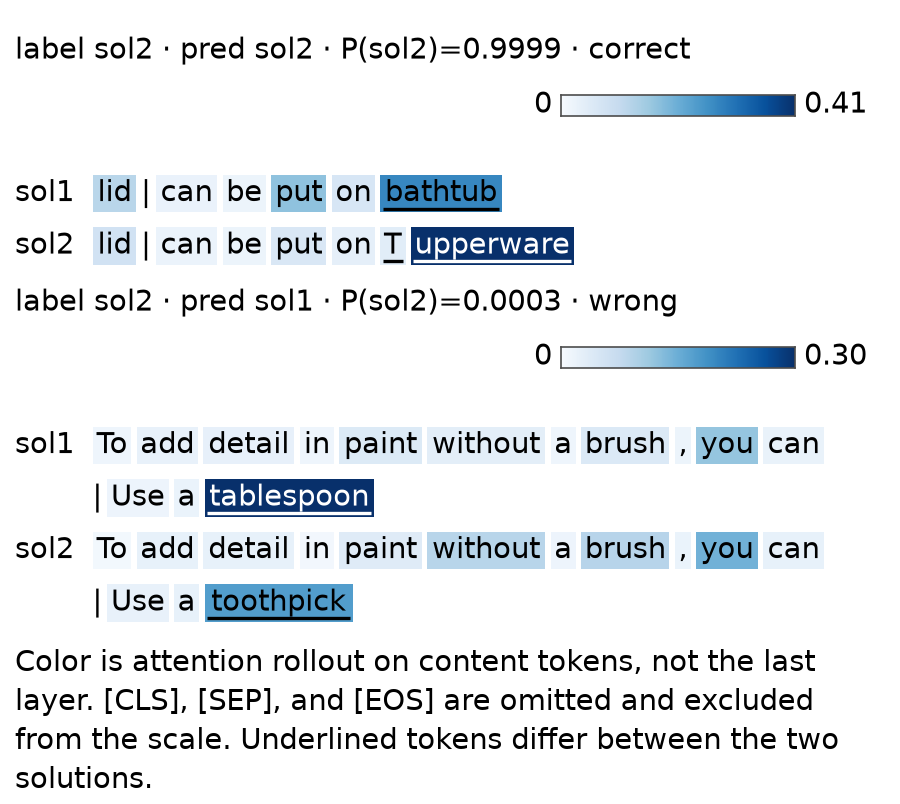

**Four validation examples. Rollout only. Differing tokens are underlined.** `reports/attention/figA_examples_compact.png`

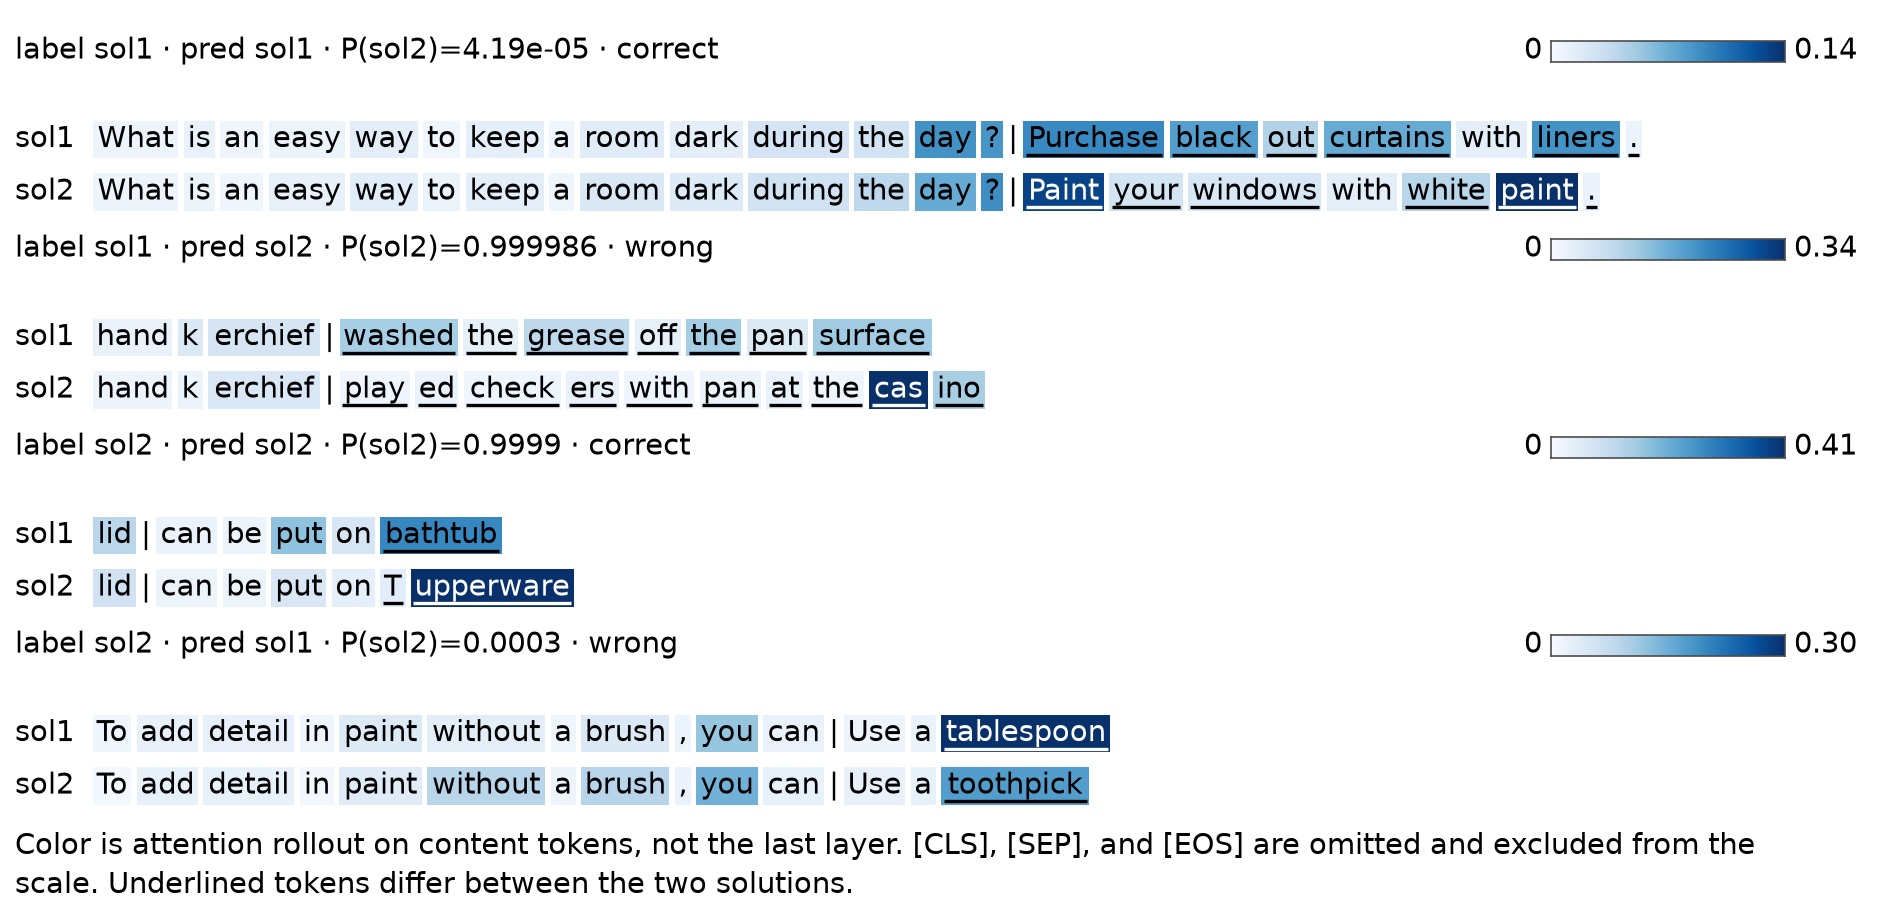

**Region shares, and validation accuracy by word-level distance.** `reports/attention/figB_share_and_accuracy_compact.png`

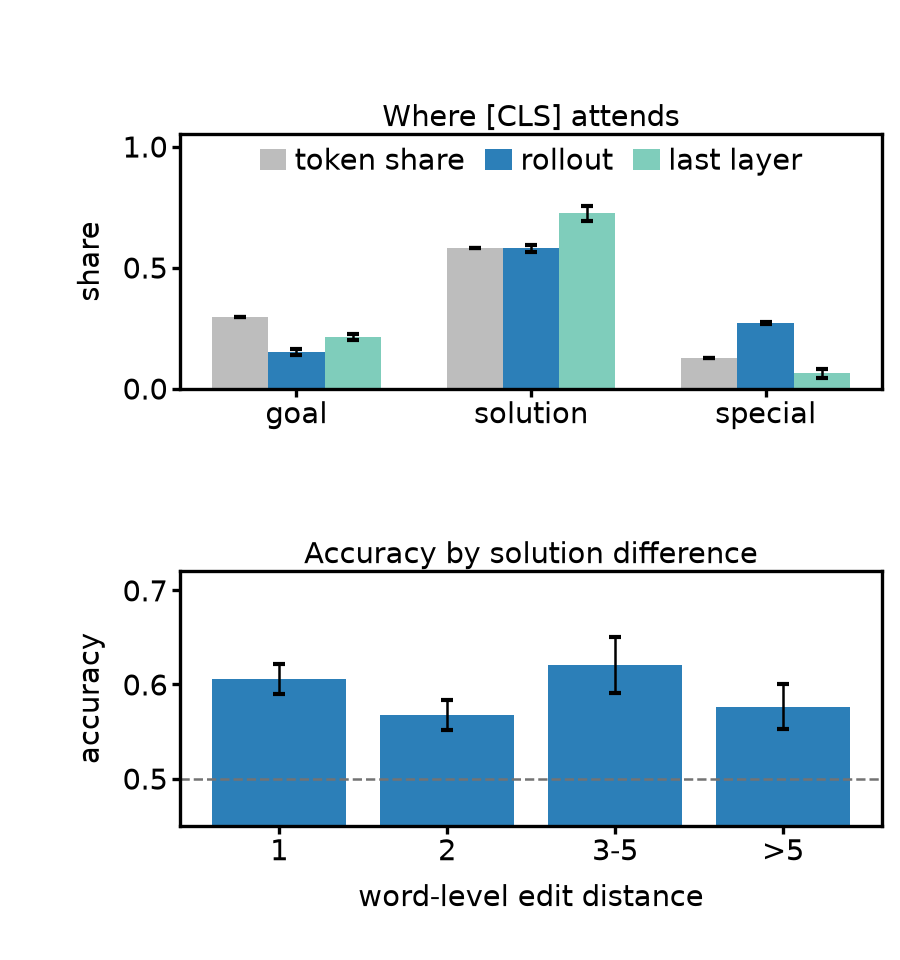

,region,token share,rollout,last layer
0,goal,0.294 ± 0.000,0.150 ± 0.013,0.213 ± 0.013
1,solution,0.581 ± 0.000,0.579 ± 0.016,0.724 ± 0.032
2,special,0.125 ± 0.000,0.271 ± 0.003,0.064 ± 0.018


,outcome,n (mean),rollout,token share
0,correct,566.3,0.116 ± 0.004,0.074 ± 0.001
1,incorrect,392.7,0.120 ± 0.003,0.081 ± 0.002


,seed,outcome,n,rollout,token share
0,4012,correct,564,"0.114 [0.106, 0.122]","0.074 [0.070, 0.079]"
1,4012,incorrect,395,"0.117 [0.107, 0.128]","0.081 [0.075, 0.087]"
2,4013,correct,565,"0.113 [0.105, 0.120]","0.073 [0.069, 0.078]"
3,4013,incorrect,394,"0.120 [0.110, 0.130]","0.083 [0.077, 0.088]"
4,4014,correct,570,"0.121 [0.113, 0.128]","0.075 [0.071, 0.080]"
5,4014,incorrect,389,"0.123 [0.114, 0.134]","0.079 [0.074, 0.086]"


,grouping,bin,n,accuracy
0,n_diff,1,568,0.606 ± 0.016
1,n_diff,2,391,0.568 ± 0.016
2,n_diff,3-5,334,0.621 ± 0.030
3,n_diff,>5,313,0.576 ± 0.024
4,length,5–20,410,0.587 ± 0.007
5,length,20–29,396,0.600 ± 0.012
6,length,29–43,404,0.621 ± 0.013
7,length,43–498,396,0.567 ± 0.015


,seed,n,delete top word,delete random word,top word is a differing word
0,4012,1606,-0.0573,-0.0082,0.392
1,4013,1606,-0.0387,-0.0059,0.402
2,4014,1606,-0.0242,-0.0061,0.402
3,mean ± sd,1606,-0.040 ± 0.017,-0.007 ± 0.001,0.398 ± 0.006


In [8]:
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

RUN_ATTENTION = False
if RUN_ATTENTION:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "scripts.analysis.attention_analysis",
            "--seeds", "4012", "4013", "4014",
            "--out", "reports/attention",
        ],
        check=True,
    )

attention_dir = Path("reports/attention")
figures = [
    (
        "figA_examples_single_compact.png",
        "Single-column examples, rows 1142 and 1296. Rollout only.",
    ),
    (
        "figA_examples_compact.png",
        "Four validation examples. Rollout only. Differing tokens are underlined.",
    ),
    (
        "figB_share_and_accuracy_compact.png",
        "Region shares, and validation accuracy by word-level distance.",
    ),
]
for filename, caption in figures:
    display(Markdown(f"**{caption}** `{attention_dir / filename}`"))
    display(Image(filename=str(attention_dir / filename)))


def fmt_ms(values, digits=3):
    mean, std = mean_std(values)
    return f"{mean:.{digits}f} ± {std:.{digits}f}"


share = pd.read_csv(attention_dir / "goal_solution_share.csv")
share_rows = []
for region in ("goal", "solution", "special"):
    token = share.loc[(share["region"] == region) & (share["source"] == "rollout"), "token_mean"]
    rollout = share.loc[(share["region"] == region) & (share["source"] == "rollout"), "attention_mean"]
    last = share.loc[(share["region"] == region) & (share["source"] == "last"), "attention_mean"]
    share_rows.append({
        "region": region,
        "token share": fmt_ms(token),
        "rollout": fmt_ms(rollout),
        "last layer": fmt_ms(last),
    })
share_table = pd.DataFrame(share_rows)
display(share_table)

diff = pd.read_csv(attention_dir / "diff_token_attention.csv")
diff_rows = []
for outcome in ("correct", "incorrect"):
    group = diff.loc[diff["outcome"] == outcome]
    diff_rows.append({
        "outcome": outcome,
        "n (mean)": f"{group['n'].mean():.1f}",
        "rollout": fmt_ms(group["attention_mean"]),
        "token share": fmt_ms(group["token_mean"]),
    })
diff_summary = pd.DataFrame(diff_rows)
display(diff_summary)

diff_seed = diff.copy()
diff_seed["rollout"] = [
    f"{mean:.3f} [{low:.3f}, {high:.3f}]"
    for mean, low, high in zip(
        diff_seed["attention_mean"], diff_seed["attention_ci_low"], diff_seed["attention_ci_high"],
    )
]
diff_seed["token share"] = [
    f"{mean:.3f} [{low:.3f}, {high:.3f}]"
    for mean, low, high in zip(
        diff_seed["token_mean"], diff_seed["token_ci_low"], diff_seed["token_ci_high"],
    )
]
display(diff_seed[["seed", "outcome", "n", "rollout", "token share"]])

errors = pd.read_csv(attention_dir / "error_by_diff.csv", dtype={"grouping": str, "bin": str})
first_seed = errors["seed"].min()
order = errors.loc[errors["seed"] == first_seed, ["grouping", "bin"]]
error_rows = []
for grouping, bin_label in order.itertuples(index=False):
    group = errors.loc[(errors["grouping"] == grouping) & (errors["bin"] == bin_label)]
    error_rows.append({
        "grouping": grouping,
        "bin": bin_label,
        "n": int(group["n"].iloc[0]),
        "accuracy": fmt_ms(group["accuracy"]),
    })
error_table = pd.DataFrame(error_rows)
display(error_table)

intervention = pd.read_csv(attention_dir / "intervention.csv")
intervention_view = pd.DataFrame({
    "seed": intervention["seed"],
    "n": intervention["n"],
    "delete top word": intervention["top_mean"].map(lambda value: f"{value:.4f}"),
    "delete random word": intervention["random_mean"].map(lambda value: f"{value:.4f}"),
    "top word is a differing word": intervention["top_is_diff_rate"].map(lambda value: f"{value:.3f}"),
})
intervention_view.loc[len(intervention_view)] = {
    "seed": "mean ± sd",
    "n": int(intervention["n"].iloc[0]),
    "delete top word": fmt_ms(intervention["top_mean"]),
    "delete random word": fmt_ms(intervention["random_mean"]),
    "top word is a differing word": fmt_ms(intervention["top_is_diff_rate"]),
}
display(intervention_view)

expected_share = {
    "goal": ("0.294 ± 0.000", "0.150 ± 0.013", "0.213 ± 0.013"),
    "solution": ("0.581 ± 0.000", "0.579 ± 0.016", "0.724 ± 0.032"),
    "special": ("0.125 ± 0.000", "0.271 ± 0.003", "0.064 ± 0.018"),
}
for region, expected in expected_share.items():
    got = share_table.loc[share_table["region"] == region].iloc[0]
    actual = (got["token share"], got["rollout"], got["last layer"])
    if actual != expected:
        raise AssertionError(f"{region} share {actual} != {expected}")

expected_diff = {
    "correct": ("0.116 ± 0.004", "0.074 ± 0.001"),
    "incorrect": ("0.120 ± 0.003", "0.081 ± 0.002"),
}
for outcome, expected in expected_diff.items():
    got = diff_summary.loc[diff_summary["outcome"] == outcome].iloc[0]
    actual = (got["rollout"], got["token share"])
    if actual != expected:
        raise AssertionError(f"{outcome} diff attention {actual} != {expected}")

expected_error = {
    ("n_diff", "1"): "0.606 ± 0.016",
    ("n_diff", "2"): "0.568 ± 0.016",
    ("n_diff", "3-5"): "0.621 ± 0.030",
    ("n_diff", ">5"): "0.576 ± 0.024",
    ("length", "5–20"): "0.587 ± 0.007",
    ("length", "20–29"): "0.600 ± 0.012",
    ("length", "29–43"): "0.621 ± 0.013",
    ("length", "43–498"): "0.567 ± 0.015",
}
for key, expected in expected_error.items():
    got = error_table.loc[
        (error_table["grouping"] == key[0]) & (error_table["bin"] == key[1]), "accuracy"
    ].item()
    if got != expected:
        raise AssertionError(f"{key} accuracy {got!r} != {expected!r}")

top_text = fmt_ms(intervention["top_mean"])
random_text = fmt_ms(intervention["random_mean"])
diff_rate_text = fmt_ms(intervention["top_is_diff_rate"])
if (top_text, random_text, diff_rate_text) != ("-0.040 ± 0.017", "-0.007 ± 0.001", "0.398 ± 0.006"):
    raise AssertionError(f"intervention {(top_text, random_text, diff_rate_text)}")


## 3.8 Summary

On the test set the frozen Transformer reaches 58.9 ± 0.2 accuracy. The no-attention BiLSTM reaches 58.3 ± 0.5, and the shorter-solution rule reaches 53.2. Zero-shot GPT-2 (61.5) and Qwen2.5-0.5B (69.5), and fine-tuned DistilBERT (62.2 ± 0.8) and RoBERTa-base (70.5 ± 0.5), score higher. Those four models are pretrained and much larger, so they are a reference for a different training regime.

On the validation set, turning positional encoding off or using a single attention head leaves accuracy close to the main model. Turning dropout off lowers accuracy, and that run peaks near epoch 11, with a much larger validation loss by epoch 300. Removing the goal at evaluation lowers accuracy on every seed. The attention rollout puts less mass on the goal than the goal's share of the sequence, which lines up with that sensitivity. The attention weights remain a correlation with the prediction.


In [9]:
import time

elapsed = time.perf_counter() - _SECTION_STARTED
minutes, seconds = divmod(elapsed, 60)
print(f"Section 3 runtime: {elapsed:.1f} s ({int(minutes)} min {seconds:.1f} s)")


Section 3 runtime: 23.4 s (0 min 23.4 s)
